# 01 — Exploratory Data Analysis

**Goal:** understand the IBM Telco churn data before any cleaning or modeling.

Covers shape, dtypes, missing values, duplicates, class balance, churn rate by segment, numeric distributions, and correlations. Exploration only: reusable logic lives in `src/`, and `data/raw` is never modified.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))  # make `src` importable

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src import config
from src.data.load import load_raw
from src.utils.seed import set_seed

set_seed()
sns.set_theme(style='whitegrid', palette='deep')
pd.set_option('display.max_columns', 30)
FIG = config.FIGURES_DIR

def save(fig, name):
    """Save a figure to reports/figures as eda_<name>.png."""
    fig.savefig(FIG / f'eda_{name}.png', dpi=120, bbox_inches='tight')

## 1. Load and overview

In [2]:
df = load_raw()
print(df.shape)
df.head()

2026-10-16 22:40:04,667 | INFO     | src.data.load | Loaded 7043 rows x 21 cols from telco_churn.csv


(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.dtypes.to_frame('dtype').T

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
dtype,str,str,int64,str,str,int64,str,str,str,str,str,str,str,str,str,str,str,str,float64,str,str


## 2. Missing values and duplicates

In [4]:
tc_blank = df['TotalCharges'].str.strip().eq('')
print('NaN cells:', int(df.isna().sum().sum()))
print('Blank TotalCharges strings:', int(tc_blank.sum()))
print('Duplicate rows:', int(df.duplicated().sum()))
print('Duplicate customerID:', int(df[config.ID_COL].duplicated().sum()))
print('Identical profiles (excluding ID):', int(df.drop(columns=config.ID_COL).duplicated().sum()))
df.loc[tc_blank, ['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']]

NaN cells: 0
Blank TotalCharges strings: 11
Duplicate rows: 0
Duplicate customerID: 0
Identical profiles (excluding ID): 22


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


**Finding:** no true missing values, but 11 `TotalCharges` are blank strings, all with `tenure == 0` (brand-new customers not yet billed). Phase 2 will set them to 0, not drop them. The 22 identical profiles are different customers with the same attributes, so they stay.

## 3. Target: class balance

Churn
No     0.7346
Yes    0.2654
Name: count, dtype: float64


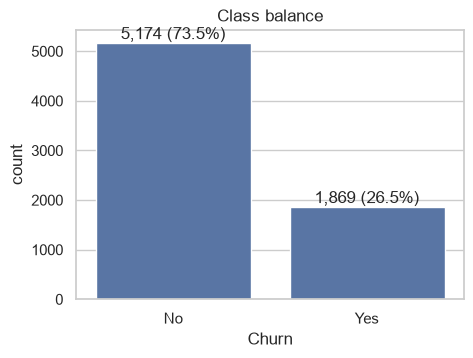

In [5]:
counts = df['Churn'].value_counts()
print((counts / len(df)).round(4))

fig, ax = plt.subplots(figsize=(5, 3.5))
sns.countplot(data=df, x='Churn', order=['No', 'Yes'], ax=ax)
for p in ax.patches:
    ax.annotate(f'{p.get_height():,.0f} ({p.get_height() / len(df):.1%})',
                (p.get_x() + p.get_width() / 2, p.get_height()), ha='center', va='bottom')
ax.set_title('Class balance')
save(fig, 'class_balance')

**Finding:** 26.5% churn — moderately imbalanced. Accuracy would be misleading (predicting 'No' for everyone scores 73%), which is why PR-AUC is the primary metric.

## 4. Numeric features

In [6]:
num = df.assign(TotalCharges=pd.to_numeric(df['TotalCharges'], errors='coerce'))
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
num.groupby('Churn')[num_cols].describe().T.round(1)

Churn                     No     Yes
tenure         count  5174.0  1869.0
               mean     37.6    18.0
               std      24.1    19.5
               min       0.0     1.0
               25%      15.0     2.0
               50%      38.0    10.0
               75%      61.0    29.0
               max      72.0    72.0
MonthlyCharges count  5174.0  1869.0
               mean     61.3    74.4
               std      31.1    24.7
               min      18.2    18.8
               25%      25.1    56.2
               50%      64.4    79.6
               75%      88.4    94.2
               max     118.8   118.4
TotalCharges   count  5163.0  1869.0
               mean   2555.3  1531.8
               std    2329.5  1890.8
               min      18.8    18.8
               25%     577.8   134.5
               50%    1683.6   703.6
               75%    4264.1  2331.3
               max    8672.4  8684.8

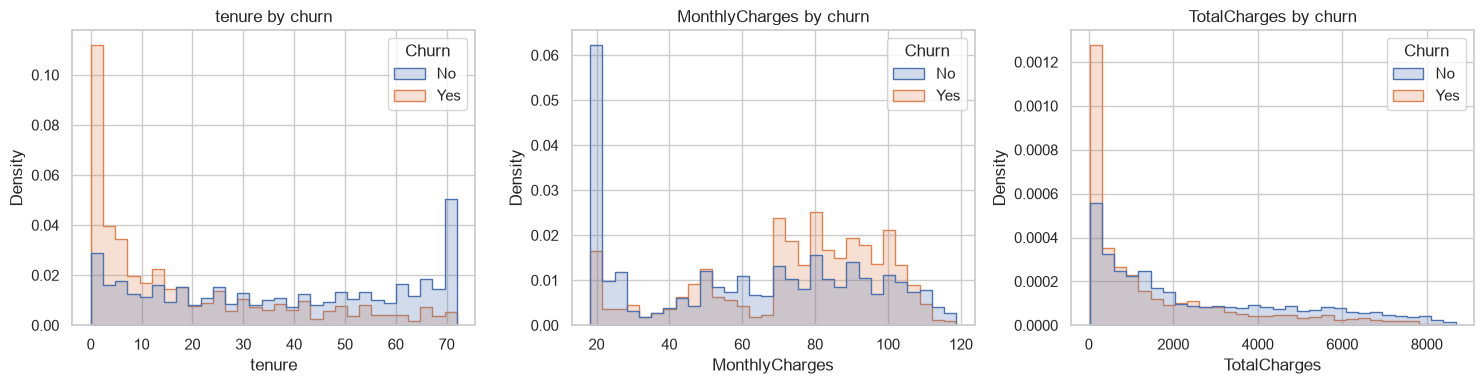

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.histplot(data=num, x=col, hue='Churn', bins=30, stat='density',
                 common_norm=False, element='step', ax=ax)
    ax.set_title(f'{col} by churn')
fig.tight_layout()
save(fig, 'numeric_distributions')

,customers,churn_rate
tenure_band,,
0-6,1481,0.529
7-12,705,0.359
13-24,1024,0.287
25-48,1594,0.204
49-72,2239,0.095


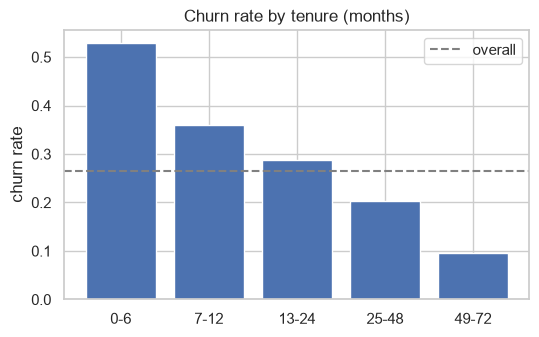

In [8]:
bins = [-1, 6, 12, 24, 48, 72]
labels = ['0-6', '7-12', '13-24', '25-48', '49-72']
tenure_rate = (num.assign(tenure_band=pd.cut(num['tenure'], bins, labels=labels))
               .groupby('tenure_band', observed=True)['Churn']
               .agg(customers='size', churn_rate=lambda s: (s == 'Yes').mean()))
display(tenure_rate.round(3))

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(tenure_rate.index.astype(str), tenure_rate['churn_rate'])
ax.axhline((df['Churn'] == 'Yes').mean(), ls='--', c='grey', label='overall')
ax.set(title='Churn rate by tenure (months)', ylabel='churn rate')
ax.legend()
save(fig, 'churn_by_tenure')

**Findings:**
- Churners have much shorter tenure (median ~10 vs ~38 months). Churn falls from **53%** in the first 6 months to **9.5%** after 4 years — the first year is the danger zone.
- Churners pay **more** per month (mean ~74 vs ~61), driven by fiber-optic plans.
- `TotalCharges` ≈ `tenure × MonthlyCharges` (ratio median 1.00), so it adds little new information and is highly collinear with tenure (r = 0.83).

## 5. Churn rate by segment (categorical features)

In [9]:
cat_cols = [c for c in df.columns if c not in (config.ID_COL, config.TARGET_COL, *num_cols)]
overall = (df['Churn'] == 'Yes').mean()

rows = []
for c in cat_cols:
    g = df.groupby(c)['Churn'].agg(customers='size', churn_rate=lambda s: (s == 'Yes').mean())
    rows.append(g.assign(feature=c).reset_index(names='value'))
seg = pd.concat(rows)[['feature', 'value', 'customers', 'churn_rate']]
seg['lift_vs_overall'] = seg['churn_rate'] / overall
spread = seg.groupby('feature')['churn_rate'].agg(lambda s: s.max() - s.min()).sort_values(ascending=False)
print('Churn-rate spread (max - min) per feature:')
spread.round(3)

Churn-rate spread (max - min) per feature:


feature
Contract            0.399
InternetService     0.345
OnlineSecurity      0.344
TechSupport         0.342
OnlineBackup        0.325
DeviceProtection    0.317
PaymentMethod       0.300
StreamingMovies     0.263
StreamingTV         0.261
SeniorCitizen       0.181
PaperlessBilling    0.172
Dependents          0.158
Partner             0.133
MultipleLines       0.037
PhoneService        0.018
gender              0.008
Name: churn_rate, dtype: float64

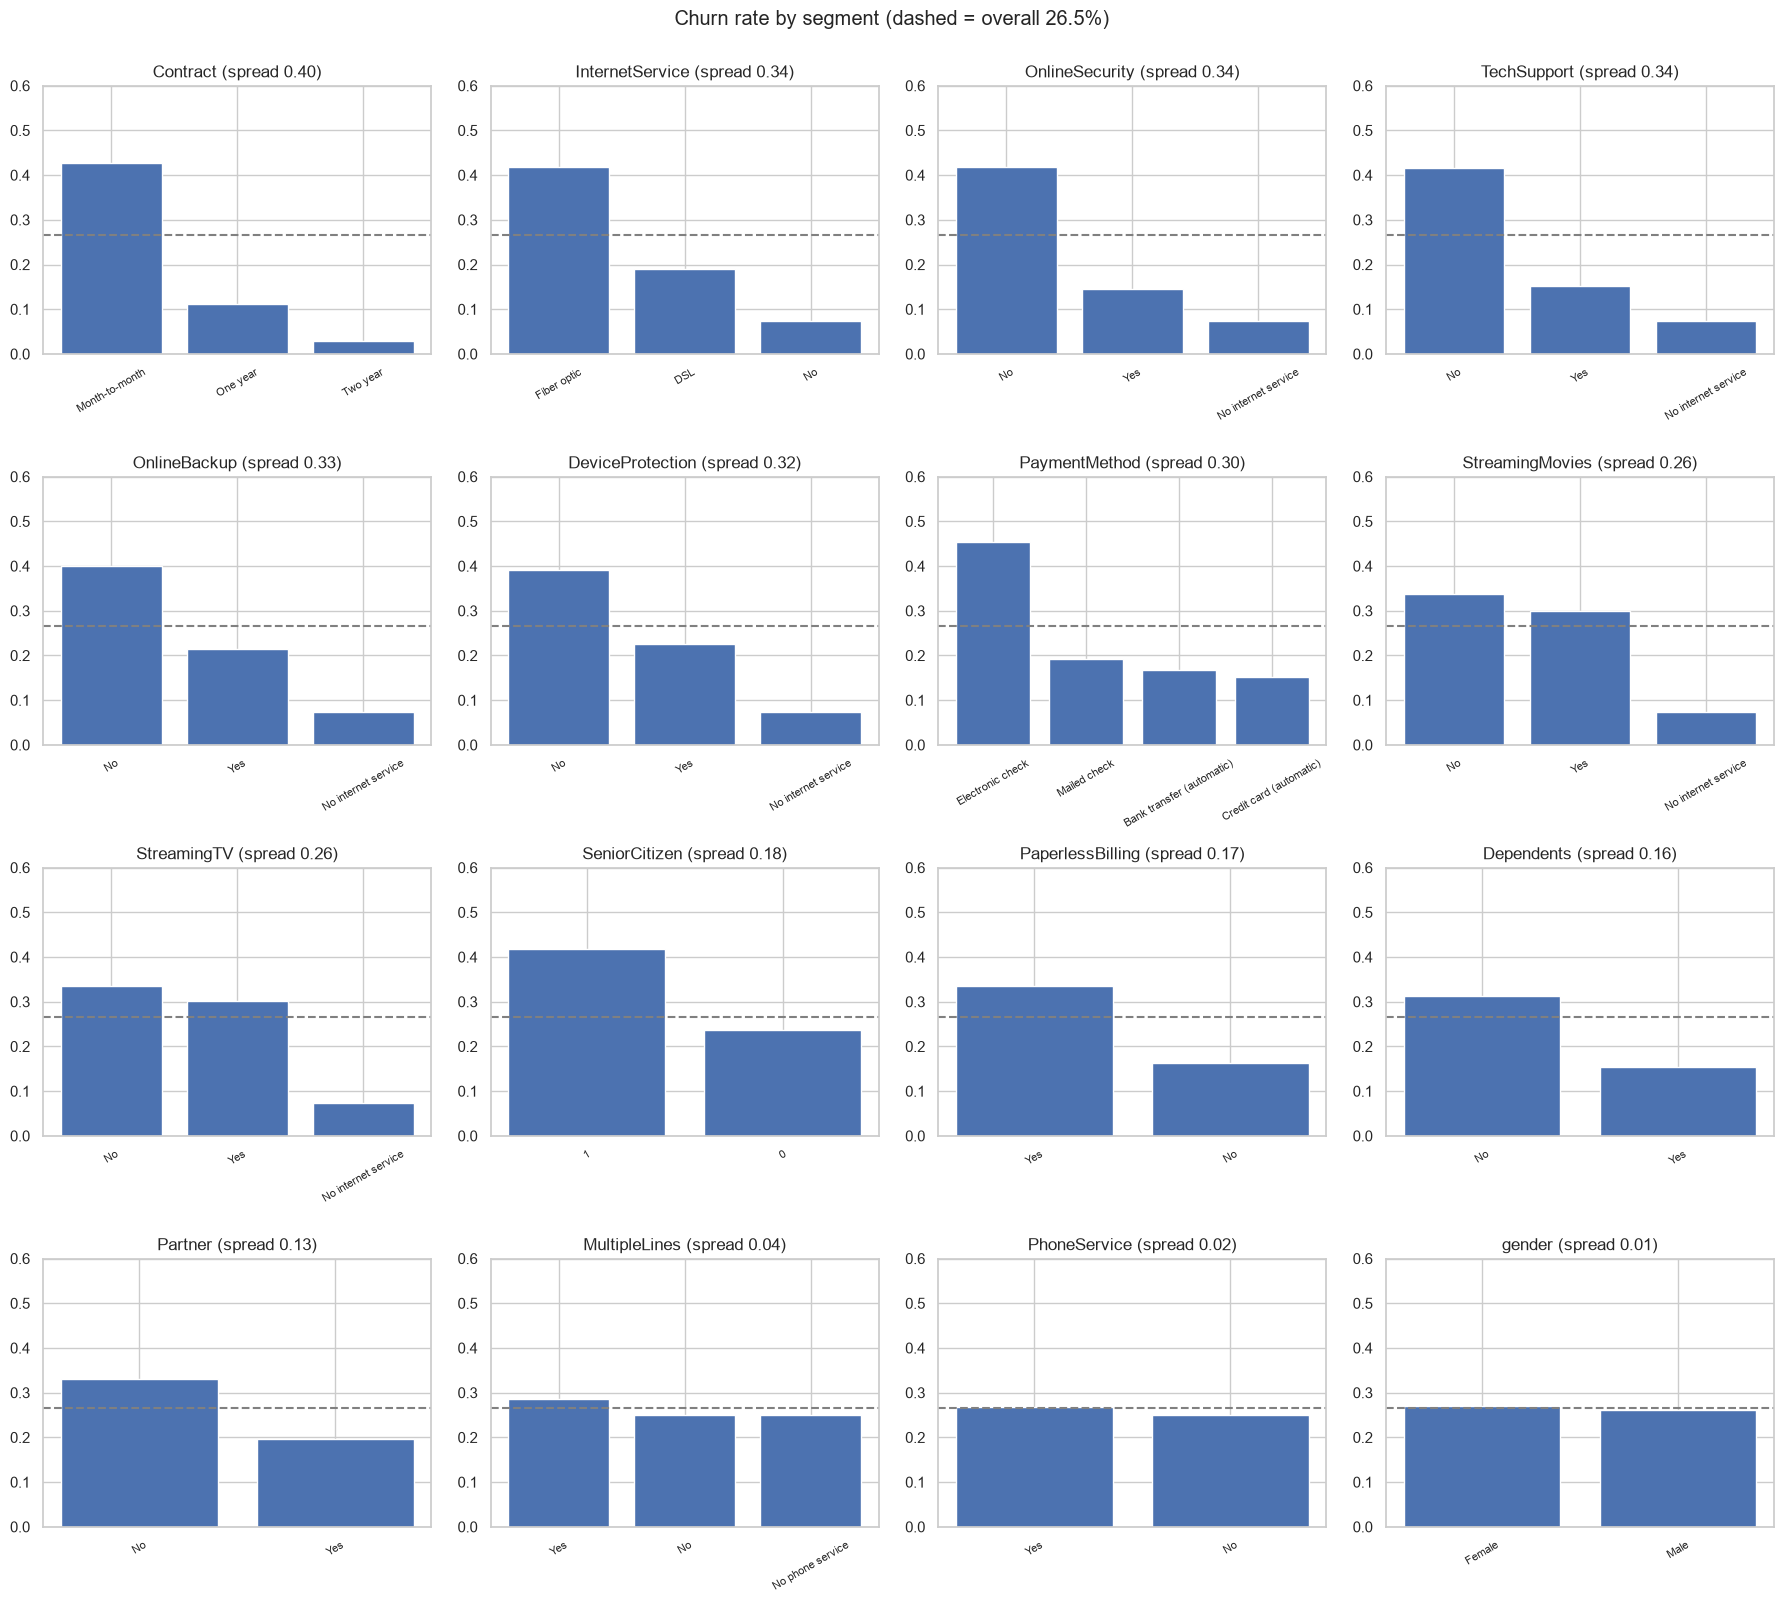

In [10]:
fig, axes = plt.subplots(4, 4, figsize=(18, 16))
for ax, c in zip(axes.flat, spread.index):
    d = seg[seg['feature'] == c].sort_values('churn_rate', ascending=False)
    ax.bar(d['value'].astype(str), d['churn_rate'])
    ax.axhline(overall, ls='--', c='grey')
    ax.set_title(f'{c} (spread {spread[c]:.2f})')
    ax.tick_params(axis='x', rotation=30, labelsize=8)
    ax.set_ylim(0, 0.6)
for ax in axes.flat[len(spread):]:
    ax.axis('off')
fig.suptitle('Churn rate by segment (dashed = overall 26.5%)', y=1.0)
fig.tight_layout()
save(fig, 'churn_by_segment')

In [11]:
seg.sort_values('churn_rate', ascending=False).head(12).round(3)

,feature,value,customers,churn_rate,lift_vs_overall
2,PaymentMethod,Electronic check,2365,0.453,1.707
0,Contract,Month-to-month,3875,0.427,1.609
1,InternetService,Fiber optic,3096,0.419,1.579
0,OnlineSecurity,No,3498,0.418,1.574
1,SeniorCitizen,1,1142,0.417,1.571
0,TechSupport,No,3473,0.416,1.569
0,OnlineBackup,No,3088,0.399,1.505
0,DeviceProtection,No,3095,0.391,1.474
0,StreamingMovies,No,2785,0.337,1.269
1,PaperlessBilling,Yes,4171,0.336,1.265


**Findings (strongest segments):**
- **Contract:** month-to-month 42.7% vs two-year 2.8% — the single strongest signal.
- **Add-on protection:** no OnlineSecurity / TechSupport ≈ 42% vs ~15% with it.
- **InternetService:** fiber optic 41.9% vs DSL 19.0%.
- **PaymentMethod:** electronic check 45.3% vs ~15–19% for the others (automatic payments are stickier).
- **SeniorCitizen** 41.7%, **no Partner** 33.0%, **no Dependents** 31.3%, **PaperlessBilling** 33.6%.
- **gender** and **PhoneService** barely differ — near-zero signal.
- The 'No internet service' level repeats across 6 add-on columns (7.4% churn) — redundant information that feature engineering can consolidate.

## 6. Correlations

tenure                                 -0.352
Contract_Two year                      -0.302
StreamingTV_No internet service        -0.228
OnlineBackup_No internet service       -0.228
DeviceProtection_No internet service   -0.228
PaymentMethod_Electronic check          0.302
InternetService_Fiber optic             0.308
TechSupport_No                          0.337
OnlineSecurity_No                       0.343
Contract_Month-to-month                 0.405
Name: Churn, dtype: float64

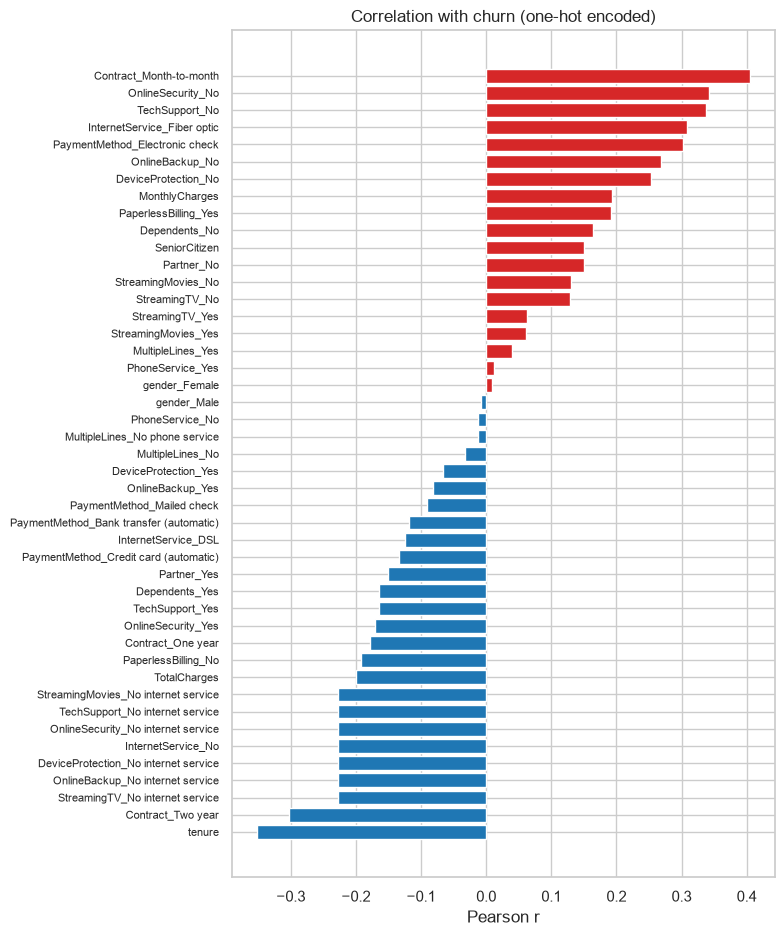

In [12]:
enc = pd.get_dummies(num.drop(columns=[config.ID_COL]).assign(
    Churn=(num['Churn'] == 'Yes').astype(int)), drop_first=False, dtype=int)
target_corr = enc.corr(numeric_only=True)['Churn'].drop('Churn').sort_values()

fig, ax = plt.subplots(figsize=(7, 11))
colors = ['tab:blue' if v < 0 else 'tab:red' for v in target_corr]
ax.barh(target_corr.index, target_corr.values, color=colors)
ax.set(title='Correlation with churn (one-hot encoded)', xlabel='Pearson r')
ax.tick_params(axis='y', labelsize=8)
save(fig, 'target_correlation')
pd.concat([target_corr.head(5), target_corr.tail(5)]).round(3)

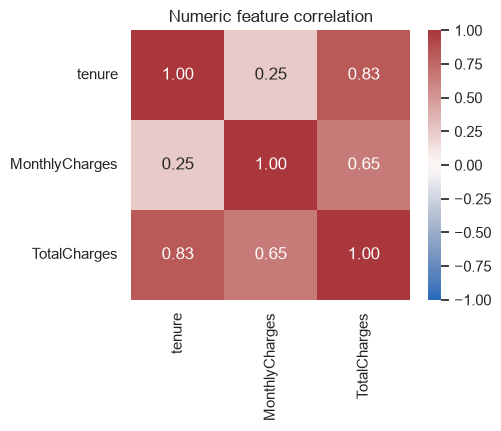

In [13]:
fig, ax = plt.subplots(figsize=(4.5, 3.5))
sns.heatmap(num[num_cols].corr(), annot=True, fmt='.2f', cmap='vlag', vmin=-1, vmax=1, ax=ax)
ax.set_title('Numeric feature correlation')
save(fig, 'numeric_correlation')

## 7. Summary and implications for later phases

| Finding | Implication |
|---|---|
| 7,043 customers, 21 columns, no duplicate IDs | One row per customer; `customerID` is the key, never a feature |
| 26.5% churn | Use PR-AUC; handle imbalance with class weights (Phase 4) |
| 11 blank `TotalCharges`, all tenure 0 | Set to 0 in cleaning (Phase 2), don't drop |
| No date column | Stratified 70/15/15 split (Phase 2) |
| Contract, tenure, internet type, payment method, add-ons dominate | Expect these to lead SHAP; good features for interactions |
| `TotalCharges` ≈ tenure × MonthlyCharges | Engineer a ratio / deviation feature instead of relying on raw value |
| 'No internet service' duplicated across 6 columns | Consolidate into a service-count feature (Phase 3) |
| gender, PhoneService ~no signal | Keep for now; let models and SHAP decide |

**Open question — snapshot leakage:** this is a single snapshot. For churners, `tenure` and `TotalCharges` stop at the churn date, so they are measured *at* churn rather than before it. This is standard for this dataset, but in production the features would be taken at a prediction date before the churn window. Flagged for the final report.